# Neural Machine Translation with an LSTM + Attention (Chinese → English)

We build a **sequence-to-sequence (seq2seq)** model that reads a Chinese sentence and writes its English translation.

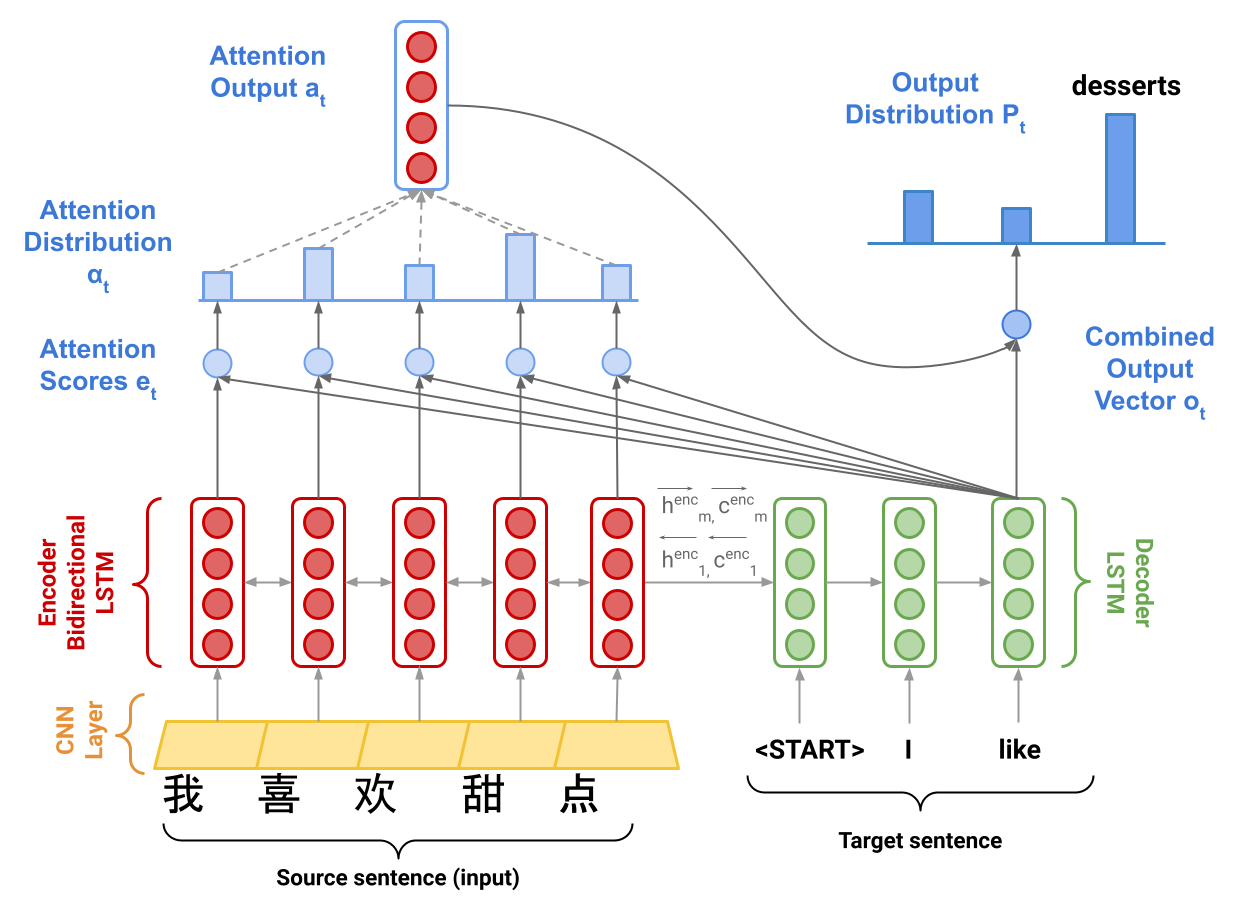

*The model on the 3rd decoder step: it has already produced "I like" and is about to produce "desserts".*

**The plan, one section each:**

1. **Data & tokenization:** split text into *subword* pieces with SentencePiece
2. **Encoder:** embeddings → 1D convolution → bidirectional LSTM
3. **Decoder + attention:** an LSTM that, at every step, *looks back* at the encoder states it needs
4. **Training:** teacher forcing + cross-entropy
5. **Decoding:** greedy search vs. beam search
6. **Evaluation:** BLEU score (with a worked example), attention heatmaps, error analysis

Everything is in this one notebook. We use PyTorch's `nn.LSTM` / `nn.LSTMCell`, `sentencepiece` for tokenization, and `sacrebleu` for BLEU.

**Data:** put the `zh_en_data` folder (or `zh_en_data.zip`) next to this notebook. On Colab, upload the zip using the file panel on the left, and select a GPU (*Runtime → Change runtime type*).

In [ ]:
!pip -q install sentencepiece sacrebleu

In [ ]:
import os, math, time, zipfile, random
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
import sentencepiece as spm
import sacrebleu

device = 'cuda' if torch.cuda.is_available() else 'cpu'
random.seed(0); torch.manual_seed(0)
print('Using device:', device)

# 1 · Data

About 200k Chinese–English sentence pairs (news text), plus 1,000-sentence dev and test sets.

In [ ]:
DATA_DIR = 'zh_en_data'
if not os.path.isdir(DATA_DIR) and os.path.exists('zh_en_data.zip'):
    with zipfile.ZipFile('zh_en_data.zip') as z:
        z.extractall('.')
assert os.path.isdir(DATA_DIR), 'Put the zh_en_data folder (or zh_en_data.zip) next to this notebook.'

def read_lines(name):
    with open(os.path.join(DATA_DIR, name), encoding='utf8') as f:
        return [line.strip() for line in f]

train_zh, train_en = read_lines('train.zh'), read_lines('train.en')
dev_zh, dev_en = read_lines('dev.zh'), read_lines('dev.en')
test_zh, test_en = read_lines('test.zh'), read_lines('test.en')
print(f'train {len(train_zh):,} | dev {len(dev_zh):,} | test {len(test_zh):,}')
for i in range(3):
    print('\nZH:', train_zh[i], '\nEN:', train_en[i])

## Tokenization: subwords with SentencePiece

A model can't read strings, so we split text into **tokens** and give each token an integer id. Options:

| Unit | Problem |
|---|---|
| Words | Huge vocabulary; any word not seen in training becomes `<unk>`. Chinese doesn't even put spaces between words. |
| Characters | Tiny vocabulary, but sequences get very long and each piece carries little meaning. |
| **Subwords** | A middle ground: frequent words stay whole, rare words are split into pieces (`unbelievable → un + believ + able`). |

**SentencePiece** *learns* a subword vocabulary from raw text, so it works for Chinese without any word segmentation.
We train one tokenizer per language (21k pieces for Chinese, 8k for English, as in the assignment).

We reserve 4 special ids: `<pad>`=0 (fill short sentences), `<unk>`=1, `<s>`=2 (start), `</s>`=3 (end).

In [ ]:
PAD, UNK, BOS, EOS = 0, 1, 2, 3

def train_tokenizer(file, prefix, vocab_size):
    if not os.path.exists(prefix + '.model'):           # train once, then reuse
        spm.SentencePieceTrainer.train(input=os.path.join(DATA_DIR, file), model_prefix=prefix,
                                       vocab_size=vocab_size, pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS)
    return spm.SentencePieceProcessor(model_file=prefix + '.model')

sp_src = train_tokenizer('train.zh', 'spm_zh', 21000)   # takes a minute or two the first time
sp_tgt = train_tokenizer('train.en', 'spm_en', 8000)
SRC_V, TGT_V = sp_src.get_piece_size(), sp_tgt.get_piece_size()

print(sp_src.encode('我喜欢甜点。', out_type=str))
print(sp_tgt.encode('i like desserts.', out_type=str))
print(sp_tgt.encode('i like desserts.'), '<- the ids the model actually sees')

Turn every sentence into ids. Target sentences get `<s>` at the start and `</s>` at the end, so the decoder knows where to begin and learns when to stop.
We drop very long training pairs to keep training fast (they're rare).

In [ ]:
MAX_LEN = 80

def encode_pairs(zh_lines, en_lines, max_len=None):
    src_ids, tgt_ids = sp_src.encode(zh_lines), sp_tgt.encode(en_lines)   # encodes a whole list at once
    pairs = []
    for s, t in zip(src_ids, tgt_ids):
        if len(s) == 0 or len(t) == 0:
            continue
        if max_len and (len(s) > max_len or len(t) > max_len):
            continue
        pairs.append((s, [BOS] + t + [EOS]))
    return pairs

train_pairs = encode_pairs(train_zh, train_en, MAX_LEN)
dev_pairs = encode_pairs(dev_zh, dev_en)
print(f'{len(train_pairs):,} training pairs kept')

## Batching: padding and packing

Sentences in a batch have different lengths, but tensors must be rectangular, so we **pad** short sentences with `<pad>` (id 0):

```
我 喜欢 甜点 。 <pad> <pad>
他 昨天 去 了 北京 。
```

Padding creates two problems we handle later:
* The **encoder LSTM** shouldn't read the pads → we use `pack_padded_sequence`, which tells the LSTM each sentence's real length.
* **Attention** shouldn't look at pads → we mask them out (Section 3).

`pad_sequence` from PyTorch does the padding for us.

In [ ]:
def collate(batch):
    src = [torch.tensor(s) for s, _ in batch]
    tgt = [torch.tensor(t) for _, t in batch]
    src_lens = torch.tensor([len(s) for s in src])
    return (pad_sequence(src, batch_first=True, padding_value=PAD), src_lens,
            pad_sequence(tgt, batch_first=True, padding_value=PAD))

BATCH_SIZE = 32
train_loader = DataLoader(train_pairs, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
dev_loader = DataLoader(dev_pairs, batch_size=64, collate_fn=collate)

src, src_lens, tgt = next(iter(train_loader))
print('src', tuple(src.shape), '| tgt', tuple(tgt.shape), '| first src lengths', src_lens[:5].tolist())

# 2 · The encoder

Notation: $m$ = source length, $e$ = embedding size, $h$ = hidden size, $b$ = batch size.

**Step 1 — Embeddings.** Each source token id → a learned vector $x_i \in \mathbb{R}^e$ (`nn.Embedding`).

**Step 2 — 1D convolution (kernel size 2).** Mixes each token with its neighbour, keeping the shape.
Why? In Chinese, characters combine into words: 电 (*electricity*) + 脑 (*brain*) = 电脑 (*computer*).
A small convolution lets the model build features for such *local combinations* before the LSTM.

**Step 3 — Bidirectional LSTM.** One LSTM reads left→right, another right→left. Their states are concatenated, so each
$h^{enc}_i \in \mathbb{R}^{2h}$ describes token $i$ *in the context of the whole sentence*.

**Step 4 — Initialize the decoder.** The forward LSTM's *last* state ($\overrightarrow{h}_m$) has read the whole sentence,
and so has the backward LSTM's state at position 1 ($\overleftarrow{h}_1$, its last step). We concatenate them and project:

$$h^{dec}_0 = W_h[\overleftarrow{h}_1;\overrightarrow{h}_m], \qquad c^{dec}_0 = W_c[\overleftarrow{c}_1;\overrightarrow{c}_m]$$

PyTorch hands us exactly these as `h_n[0]` (forward, final) and `h_n[1]` (backward, final).

# 3 · The decoder with attention

**The bottleneck problem:** without attention, the whole source sentence must be squeezed into one vector $h^{dec}_0$.
Long sentences don't fit. **Attention** lets the decoder look at *all* encoder states at every step and pick what it needs.

On decoder step $t$:

| Quantity | Formula | Shape | Meaning |
|---|---|---|---|
| input | $\bar{y}_t = [y_t; o_{t-1}]$ | $e+h$ | previous word's embedding **+** previous combined output (*input feeding*) |
| LSTM step | $h^{dec}_t, c^{dec}_t = \text{LSTMCell}(\bar{y}_t, h^{dec}_{t-1}, c^{dec}_{t-1})$ | $h$ | |
| scores | $e_{t,i} = (h^{dec}_t)^\top W_{att}\, h^{enc}_i$ | $m$ | how relevant is source token $i$ right now? (*multiplicative* attention) |
| weights | $\alpha_t = \text{softmax}(e_t)$ | $m$ | a probability distribution over source tokens |
| attention output | $a_t = \sum_i \alpha_{t,i}\, h^{enc}_i$ | $2h$ | weighted average of encoder states |
| combined output | $o_t = \text{dropout}(\tanh(W_u[a_t; h^{dec}_t]))$ | $h$ | |
| word probabilities | $P_t = \text{softmax}(W_{vocab}\, o_t)$ | $V$ | |

**Masking:** before the softmax, we set the scores at `<pad>` positions to $-\infty$. Then $e^{-\infty}=0$, so pads get
exactly **zero** attention weight and can't leak into $a_t$. Without the mask, the model would attend to meaningless padding,
and a sentence's translation would depend on how long the *other* sentences in its batch were.

**Input feeding:** feeding $o_{t-1}$ back in tells the decoder what it attended to last step, which helps it keep track of what has already been translated.

**Precompute:** $W_{att} h^{enc}_i$ doesn't depend on $t$, so we compute it once for all positions (`enc_proj`).

In [ ]:
class NMT(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, embed_size=256, hidden_size=256, dropout=0.3):
        super().__init__()
        E, H = embed_size, hidden_size
        self.hidden_size = H
        self.src_embed = nn.Embedding(src_vocab, E, padding_idx=PAD)
        self.tgt_embed = nn.Embedding(tgt_vocab, E, padding_idx=PAD)
        self.conv = nn.Conv1d(E, E, kernel_size=2, padding='same')
        self.encoder = nn.LSTM(E, H, bidirectional=True, batch_first=True)
        self.decoder = nn.LSTMCell(E + H, H)
        self.h_proj = nn.Linear(2 * H, H, bias=False)          # W_h
        self.c_proj = nn.Linear(2 * H, H, bias=False)          # W_c
        self.att_proj = nn.Linear(2 * H, H, bias=False)        # W_att
        self.combined_proj = nn.Linear(3 * H, H, bias=False)   # W_u
        self.vocab_proj = nn.Linear(H, tgt_vocab, bias=False)  # W_vocab
        self.dropout = nn.Dropout(dropout)

    def encode(self, src, src_lens):
        """src: (b, m) padded ids -> enc_h: (b, m, 2h), decoder initial state (h0, c0)"""
        X = self.src_embed(src)                                   # (b, m, e)
        X = self.conv(X.transpose(1, 2)).transpose(1, 2)          # Conv1d wants (b, channels, length)
        packed = pack_padded_sequence(X, src_lens.cpu(), batch_first=True, enforce_sorted=False)
        out, (h_n, c_n) = self.encoder(packed)                    # h_n, c_n: (2, b, h) = [forward, backward]
        enc_h, _ = pad_packed_sequence(out, batch_first=True, total_length=src.size(1))   # (b, m, 2h)
        h0 = self.h_proj(torch.cat([h_n[0], h_n[1]], dim=1))      # (b, h)
        c0 = self.c_proj(torch.cat([c_n[0], c_n[1]], dim=1))
        return enc_h, (h0, c0)

    def step(self, ybar, state, enc_h, enc_proj, src_mask):
        """One decoder step. ybar: (b, e+h). Returns new state, o_t (b, h), attention weights (b, m)."""
        h, c = self.decoder(ybar, state)
        scores = torch.bmm(enc_proj, h.unsqueeze(2)).squeeze(2)    # (b, m)   e_t
        if src_mask is not None:
            scores = scores.masked_fill(src_mask, float('-inf'))   # pads get 0 weight after softmax
        alpha = F.softmax(scores, dim=1)                           # (b, m)   alpha_t
        a = torch.bmm(alpha.unsqueeze(1), enc_h).squeeze(1)        # (b, 2h)  a_t
        o = self.dropout(torch.tanh(self.combined_proj(torch.cat([a, h], dim=1))))   # (b, h)  o_t
        return (h, c), o, alpha

    def forward(self, src, src_lens, tgt):
        """Teacher forcing. Returns (summed cross-entropy loss, number of target words)."""
        enc_h, state = self.encode(src, src_lens)
        enc_proj = self.att_proj(enc_h)                            # computed once, reused every step
        src_mask = src == PAD
        Y = self.tgt_embed(tgt[:, :-1])                            # inputs:  <s> w1 w2 ...
        o_prev = torch.zeros(src.size(0), self.hidden_size, device=src.device)
        outputs = []
        for t in range(Y.size(1)):
            state, o_prev, _ = self.step(torch.cat([Y[:, t], o_prev], dim=1), state, enc_h, enc_proj, src_mask)
            outputs.append(o_prev)
        logits = self.vocab_proj(torch.stack(outputs, dim=1))      # (b, T, V)
        targets = tgt[:, 1:]                                       # targets: w1 w2 ... </s>
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1),
                               ignore_index=PAD, reduction='sum')
        return loss, (targets != PAD).sum()

**Shape check** on one batch before training anything:

In [ ]:
model = NMT(SRC_V, TGT_V).to(device)
loss, n_words = model(src.to(device), src_lens, tgt.to(device))
print(f'loss per word at init: {loss.item() / n_words.item():.2f}  (≈ ln(V) = {math.log(TGT_V):.2f} for a random model)')
print(f'parameters: {sum(p.numel() for p in model.parameters()):,}')

# 4 · Training

**Teacher forcing:** during training the decoder always receives the *true* previous word, not its own guess. That's what
makes the loop above possible in one pass: the inputs are `<s> w1 w2 …`, the targets are the same sentence shifted by one, `w1 w2 … </s>`.
The loss is the cross-entropy of predicting each target word (pads ignored).

Details that matter for RNNs (all from the original assignment):
* **Uniform init** in $[-0.1, 0.1]$ for every parameter.
* **Gradient clipping** (norm 5): backpropagating through many time steps can occasionally produce huge gradients; clipping caps their size.
* **Learning-rate decay:** halve the learning rate when dev perplexity stops improving (`ReduceLROnPlateau`).

We report **perplexity** $= \exp(\text{average loss per word})$: roughly, "how many words is the model choosing between". Lower is better.

In [ ]:
@torch.no_grad()
def perplexity(model, loader):
    model.eval()
    total_loss, total_words = 0.0, 0
    for src, src_lens, tgt in loader:
        loss, n = model(src.to(device), src_lens, tgt.to(device))
        total_loss += loss.item(); total_words += n.item()
    return math.exp(total_loss / total_words)

def train(model, epochs, lr=5e-4, clip=5.0, eval_every=2000, log_every=200, save_path='nmt_best.pt'):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)
    best = {'ppl': float('inf')}
    history, step, start = [], 0, time.time()

    def validate():                      # dev perplexity -> LR schedule + keep the best weights
        dev_ppl = perplexity(model, dev_loader)
        history.append((step, dev_ppl))
        scheduler.step(dev_ppl)
        tag = ''
        if dev_ppl < best['ppl']:
            best['ppl'] = dev_ppl
            torch.save(model.state_dict(), save_path)
            tag = '  (best, saved)'
        print(f'  >> dev ppl {dev_ppl:.2f}  lr {optimizer.param_groups[0]["lr"]:.1e}{tag}')

    for epoch in range(epochs):
        for src, src_lens, tgt in train_loader:
            model.train()
            loss, n_words = model(src.to(device), src_lens, tgt.to(device))
            optimizer.zero_grad()
            (loss / src.size(0)).backward()                        # loss per sentence, as in the assignment
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            optimizer.step()
            step += 1
            if step % log_every == 0:
                print(f'epoch {epoch + 1} step {step:6d} | train ppl {math.exp(loss.item() / n_words.item()):7.2f} '
                      f'| {time.time() - start:5.0f}s')
            if step % eval_every == 0:
                validate()
        print(f'--- end of epoch {epoch + 1}')
        validate()
    model.load_state_dict(torch.load(save_path))                   # keep the best checkpoint
    return history

**Sanity check first:** a model that's correct can memorize a tiny dataset. Train on 100 pairs; the training perplexity should drop close to 1.

In [ ]:
tiny_loader = DataLoader(train_pairs[:100], batch_size=20, shuffle=True, collate_fn=collate)
tiny = NMT(SRC_V, TGT_V).to(device)
opt = torch.optim.Adam(tiny.parameters(), lr=1e-3)
for it in range(1, 201):
    for src, src_lens, tgt in tiny_loader:
        loss, n = tiny(src.to(device), src_lens, tgt.to(device))
        opt.zero_grad(); (loss / src.size(0)).backward(); opt.step()
    if it % 50 == 0:
        print(f'iteration {it}: train ppl {math.exp(loss.item() / n.item()):.2f}')
del tiny

**Full training.** This is the slow part: the original assignment budgets about 1.5–2 hours on a GPU.
The official solution reached a test BLEU of about **20** after ~4 epochs (the assignment asks for > 18).
For a quicker look, lower `EPOCHS` or train on a slice, e.g. `train_loader = DataLoader(train_pairs[:50000], ...)`.

In [ ]:
EPOCHS = 4
model = NMT(SRC_V, TGT_V).to(device)
for p in model.parameters():
    nn.init.uniform_(p, -0.1, 0.1)
history = train(model, EPOCHS)

In [ ]:
if history:
    plt.plot(*zip(*history), '-o'); plt.xlabel('training step'); plt.ylabel('dev perplexity'); plt.grid(alpha=0.3); plt.show()
print(f'final dev perplexity: {perplexity(model, dev_loader):.2f}')

# 5 · Decoding: turning probabilities into a sentence

At test time there's no true previous word: the decoder must feed its **own** output back in, starting from `<s>` and stopping at `</s>`.

**Greedy decoding:** always take the single most likely next word. Fast, but a choice that looks best now can lead to a bad sentence later — and it can never be undone.

**Beam search:** keep the $k$ best *partial* translations (the "beam"). At each step, extend each of them by every possible word,
score each candidate by its total log-probability $\sum_t \log P(y_t \mid y_{<t}, x)$, and keep the top $k$.
A hypothesis that produces `</s>` is finished. In the end, return the best finished hypothesis.

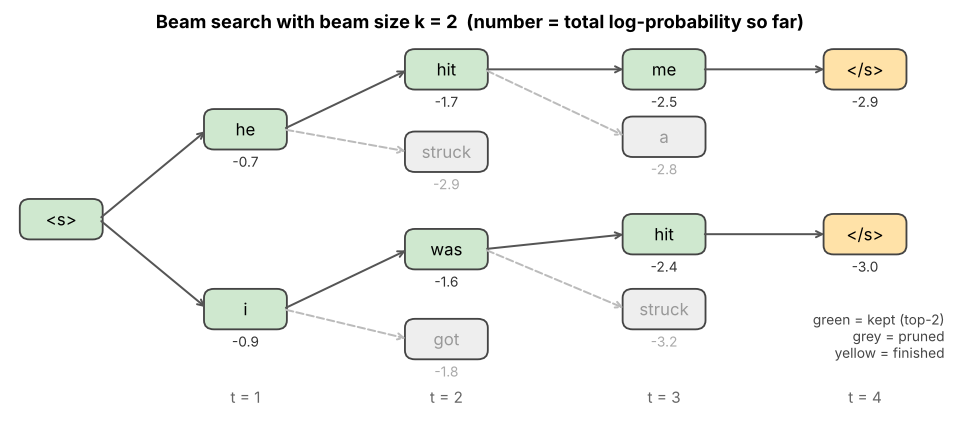

Note: summed log-probabilities favour **short** outputs (every extra word adds a negative number). Real systems often divide by length; we keep the plain version from the assignment.

In [ ]:
@torch.no_grad()
def greedy_translate(model, zh_sentence, max_len=70):
    """Returns the English translation, the source pieces, the output pieces, and the attention matrix."""
    model.eval()
    ids = sp_src.encode(zh_sentence) or [UNK]          # guard against an empty line
    src = torch.tensor([ids], device=device)
    enc_h, state = model.encode(src, torch.tensor([len(ids)]))
    enc_proj = model.att_proj(enc_h)
    y = torch.tensor([BOS], device=device)
    o_prev = torch.zeros(1, model.hidden_size, device=device)
    out_ids, attentions = [], []
    for _ in range(max_len):
        state, o_prev, alpha = model.step(torch.cat([model.tgt_embed(y), o_prev], 1), state, enc_h, enc_proj, None)
        y = model.vocab_proj(o_prev).argmax(dim=1)       # most likely next word
        if y.item() == EOS:
            break
        out_ids.append(y.item()); attentions.append(alpha[0].cpu())
    att = torch.stack(attentions) if attentions else torch.zeros(0, len(ids))
    return sp_tgt.decode(out_ids), sp_src.id_to_piece(ids), sp_tgt.id_to_piece(out_ids), att

@torch.no_grad()
def beam_search(model, zh_sentence, beam_size=5, max_len=70):
    model.eval()
    ids = sp_src.encode(zh_sentence) or [UNK]          # guard against an empty line
    src = torch.tensor([ids], device=device)
    enc_h, (h, c) = model.encode(src, torch.tensor([len(ids)]))
    enc_proj = model.att_proj(enc_h)
    o_prev = torch.zeros(1, model.hidden_size, device=device)
    hyps, scores = [[BOS]], torch.zeros(1, device=device)     # live hypotheses and their log-probs
    finished = []
    for _ in range(max_len):
        n = len(hyps)
        y = model.tgt_embed(torch.tensor([hyp[-1] for hyp in hyps], device=device))
        (h, c), o_prev, _ = model.step(torch.cat([y, o_prev], 1), (h, c),
                                       enc_h.expand(n, -1, -1), enc_proj.expand(n, -1, -1), None)
        log_p = F.log_softmax(model.vocab_proj(o_prev), dim=-1)                  # (n, V)
        candidates = (scores.unsqueeze(1) + log_p).view(-1)                      # score of every (hypothesis, word)
        top_scores, top_idx = candidates.topk(beam_size - len(finished))
        new_hyps, keep, new_scores = [], [], []
        for score, idx in zip(top_scores.tolist(), top_idx.tolist()):
            prev, word = divmod(idx, log_p.size(1))                              # which hypothesis, which word
            if word == EOS:
                finished.append((hyps[prev][1:], score))
            else:
                new_hyps.append(hyps[prev] + [word]); keep.append(prev); new_scores.append(score)
        if len(finished) >= beam_size or not new_hyps:
            break
        keep = torch.tensor(keep, device=device)
        h, c, o_prev = h[keep], c[keep], o_prev[keep]                            # carry each survivor's state
        hyps, scores = new_hyps, torch.tensor(new_scores, device=device)
    if not finished:
        finished = [(hyps[0][1:], scores[0].item())]
    best_ids, _ = max(finished, key=lambda f: f[1])
    return sp_tgt.decode(best_ids)

In [ ]:
for i in [0, 5, 10]:
    print('ZH    :', test_zh[i])
    print('REF   :', test_en[i])
    print('GREEDY:', greedy_translate(model, test_zh[i])[0])
    print('BEAM  :', beam_search(model, test_zh[i]))
    print()

# 6 · Evaluation

## BLEU: how it works

BLEU compares a candidate translation $c$ with one or more human references $r_1 \dots r_k$ by counting overlapping **n-grams**.

**Modified n-gram precision** — of the candidate's n-grams, how many appear in a reference? Each n-gram's count is
*clipped* to the most times it appears in any single reference, so repeating "the the the" isn't rewarded:

$$p_n = \frac{\sum_{\text{ngram} \in c} \min\big(\max_i \text{Count}_{r_i}(\text{ngram}),\ \text{Count}_c(\text{ngram})\big)}{\sum_{\text{ngram} \in c} \text{Count}_c(\text{ngram})}$$

**Brevity penalty** — precision alone rewards very short outputs, so short candidates are penalized
($len(r)$ = length of the reference closest in length to $c$):

$$BP = \begin{cases}1 & len(c) \ge len(r)\\ e^{\,1 - len(r)/len(c)} & \text{otherwise}\end{cases}
\qquad BLEU = BP \cdot \exp\Big(\sum_n \lambda_n \log p_n\Big)$$

The worked example from the assignment (using only 1- and 2-grams, $\lambda_1 = \lambda_2 = 0.5$):

In [ ]:
from collections import Counter

def ngrams(words, n):
    return Counter(tuple(words[i:i + n]) for i in range(len(words) - n + 1))

def bleu(candidate, references, weights=(0.5, 0.5)):
    c = candidate.split(); refs = [r.split() for r in references]
    log_sum = 0.0
    for n, w in enumerate(weights, start=1):
        cand_counts = ngrams(c, n)
        clipped = sum(min(cnt, max(ngrams(r, n)[g] for r in refs)) for g, cnt in cand_counts.items())
        p_n = clipped / max(sum(cand_counts.values()), 1)
        print(f'  p_{n} = {clipped}/{sum(cand_counts.values())} = {p_n:.3f}')
        log_sum += w * math.log(p_n) if p_n > 0 else float('-inf')
    len_r = min((abs(len(r) - len(c)), len(r)) for r in refs)[1]     # closest length, ties -> shorter
    bp = 1.0 if len(c) >= len_r else math.exp(1 - len_r / len(c))
    print(f'  len(c) = {len(c)}, len(r) = {len_r}, BP = {bp:.3f}')
    return bp * math.exp(log_sum)

refs = ['resources have to be sufficient and they have to be predictable',
        'adequate and predictable resources are required']
for cand in ['there is a need for adequate and predictable resources',
             'resources be sufficient and predictable to']:
    print(cand)
    print(f'  BLEU = {bleu(cand, refs):.3f}\n')

The second candidate scores higher, even though the first is clearly the better English. That's BLEU's big weakness:
it rewards **word overlap**, not meaning or fluency. A good translation that uses different words than the reference(s) gets punished.
It's still useful for comparing systems on a large test set, where these effects average out.

## BLEU on the test set

`sacrebleu` is the standard implementation (corpus-level, 1–4-grams, scale 0–100). Beam search over 1,000 sentences takes a few minutes.

In [ ]:
greedy_hyps = [greedy_translate(model, s)[0] for s in test_zh]
print(f'greedy BLEU: {sacrebleu.corpus_bleu(greedy_hyps, [test_en]).score:.2f}')

beam_hyps = [beam_search(model, s, beam_size=5) for s in test_zh]
print(f'beam   BLEU: {sacrebleu.corpus_bleu(beam_hyps, [test_en]).score:.2f}')

## What is the model looking at?

Each row of the heatmap is one generated English piece; each column is one Chinese piece. Bright = high attention weight $\alpha_{t,i}$.
For a good model you'll see a rough diagonal (both languages share a lot of word order) with jumps where the order differs.

Matplotlib needs a font with Chinese characters. On Colab, run the next cell once; elsewhere, install any CJK font (e.g. Noto Sans CJK).

In [ ]:
# Colab / Debian / Ubuntu only — installs a font with Chinese characters
!apt-get -qq install -y fonts-noto-cjk > /dev/null

In [ ]:
from matplotlib import font_manager
cjk = [f for f in font_manager.findSystemFonts() if 'CJK' in f or 'SimHei' in f or 'PingFang' in f or 'msyh' in f]
if cjk:
    font_manager.fontManager.addfont(cjk[0])
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=cjk[0]).get_name()
else:
    print('No CJK font found: Chinese labels will show as boxes, the heatmap is still correct.')

def show_attention(zh_sentence):
    translation, src_pieces, out_pieces, att = greedy_translate(model, zh_sentence)
    fig, ax = plt.subplots(figsize=(0.5 * len(src_pieces) + 2, 0.4 * len(out_pieces) + 2))
    ax.imshow(att.numpy(), cmap='viridis')
    ax.set_xticks(range(len(src_pieces))); ax.set_xticklabels(src_pieces, rotation=90)
    ax.set_yticks(range(len(out_pieces))); ax.set_yticklabels(out_pieces)
    ax.set_title(translation, fontsize=10); plt.tight_layout(); plt.show()

show_attention(test_zh[0])
show_attention('我喜欢甜点。')

## Error analysis: why NMT systems make mistakes

These are real errors from a model like ours (taken from the assignment), with typical causes and fixes:

| Source | Reference | Model output | Error & likely cause | Possible fix |
|---|---|---|---|---|
| 贼人其后被警方拘捕… | **the culprits were** arrested… | **the culprit was** arrested… | Number (plural → singular). Chinese doesn't mark plurals on nouns, so the model must infer it from context. | More data; a stronger encoder that uses context. |
| 几乎已经没有地方容纳这些人,资源已经用尽。 | there is almost no space… and resources have run out | resources have been exhausted and **resources have been exhausted** | Repetition: the decoder doesn't track which source parts it already covered. | *Coverage* penalties/attention that discourage attending to the same words again. |
| 当局已经宣布今天是**国殇日**。 | …a **national mourning** today | …**today's day** | Rare, culturally specific term translated piece by piece. | More/varied data; better handling of rare words. |
| 俗语有云:"唔做唔错"。 | "**act not, err not**", so a saying goes | as the saying goes, "**it's not wrong**" | Idiom (and Cantonese!) translated literally. | Training data with idioms; a pretrained model with broader knowledge. |

Other common ones: dropping words in long sentences, wrong word order, and hallucinating fluent text that isn't in the source.

## Takeaways

* **Subword tokenization** (SentencePiece) handles rare words and languages without spaces.
* **Encoder:** embeddings → 1D conv (local combinations like 电+脑) → **bidirectional LSTM** (each token sees the whole sentence).
* **Attention** removes the single-vector bottleneck: every step computes scores against all encoder states, softmaxes them, and takes a weighted average. **Masks** set pad scores to $-\infty$ so pads get zero weight.
* **Teacher forcing** in training (feed true words); **greedy or beam search** at test time (feed own predictions).
* **BLEU** = clipped n-gram precision × brevity penalty. Useful for comparing systems, but blind to meaning and paraphrase.
* `pack_padded_sequence`, `nn.LSTM`, `nn.LSTMCell`, `ReduceLROnPlateau`, `clip_grad_norm_` do the heavy lifting; the parts worth writing by hand are attention and decoding.